In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Loading the datasets

orders = pd.read_csv("orders.csv",parse_dates=['order_date'])
order_items = pd.read_csv("order_items.csv")
products = pd.read_csv('products.csv')
customers = pd.read_csv('customers.csv')

# Displaying the size of each dataset
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)

Orders: (9245, 7)
Order Items: (15608, 5)
Products: (90, 5)
Customers: (3600, 4)


In [37]:
print("Oders")
orders.info()

print("\n Orders_items")
order_items.info()

print("\nProducts")
products.info()

print("\nCustomers")
customers.info()

Oders
<class 'pandas.DataFrame'>
RangeIndex: 9245 entries, 0 to 9244
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        9245 non-null   int64         
 1   customer_id     9245 non-null   int64         
 2   order_date      9245 non-null   datetime64[us]
 3   status          9245 non-null   str           
 4   payment_method  9245 non-null   str           
 5   discount_code   1411 non-null   str           
 6   shipping_fee    9245 non-null   float64       
dtypes: datetime64[us](1), float64(1), int64(2), str(3)
memory usage: 685.5 KB

 Orders_items
<class 'pandas.DataFrame'>
RangeIndex: 15608 entries, 0 to 15607
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         15608 non-null  int64  
 1   product_id       15608 non-null  int64  
 2   quantity         15608 non-null  int64  
 3   unit_

In [38]:
dataset = {
    "orders":orders,
    "order_items":order_items,
    "products":products,
    "customers":customers
}

for name,df in dataset.items():
    print(f'\n --- {name.upper()} ---')
    print("Duplicate rows:",df.duplicated().sum())
    print("\nMissing Values:")
    print(df.isnull().sum())


 --- ORDERS ---
Duplicate rows: 38

Missing Values:
order_id             0
customer_id          0
order_date           0
status               0
payment_method       0
discount_code     7834
shipping_fee         0
dtype: int64

 --- ORDER_ITEMS ---
Duplicate rows: 0

Missing Values:
order_id             0
product_id           0
quantity             0
unit_price         199
discount_amount      0
dtype: int64

 --- PRODUCTS ---
Duplicate rows: 0

Missing Values:
product_id      0
product_name    0
category        0
list_price      0
unit_cost       0
dtype: int64

 --- CUSTOMERS ---
Duplicate rows: 0

Missing Values:
customer_id            0
signup_date            0
state                  0
acquisition_channel    0
dtype: int64


In [39]:
# Check A: Are order IDs duplicated?

# Check duplicate order IDs
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())

# Display duplicate order records
print(
    orders[orders["order_id"].duplicated(keep=False)]
    .sort_values("order_id")
    .head(20)
)

Duplicate order IDs: 38
      order_id  customer_id          order_date     status payment_method  \
47      100048         3320 2024-01-06 16:37:36  completed    credit_card   
8560    100048         3320 2024-01-06 16:37:36  completed    credit_card   
7556    100303          853 2024-02-03 08:33:22  completed      apple_pay   
303     100303          853 2024-02-03 08:33:22  completed      apple_pay   
5488    100710          526 2024-03-13 13:39:17  completed    credit_card   
712     100710          526 2024-03-13 13:39:17  completed    credit_card   
781     100779         1209 2024-03-20 11:07:55  completed      gift_card   
6700    100779         1209 2024-03-20 11:07:55  completed      gift_card   
2747    101380         2821 2024-05-15 16:28:12  completed    credit_card   
1383    101380         2821 2024-05-15 16:28:12  completed    credit_card   
8406    101813          464 2024-06-23 07:28:13  completed    credit_card   
1818    101813          464 2024-06-23 07:28:13  com

In [40]:
# Check B: Inspect categories, statuses and payment methods

print("Order statuses:")
print(orders["status"].value_counts(dropna=False))

print("\nPayment methods:")
print(orders["payment_method"].value_counts(dropna=False))

print("\nProduct categories:")
print(products["category"].value_counts(dropna=False))

Order statuses:
status
completed    8490
returned      409
canceled      346
Name: count, dtype: int64

Payment methods:
payment_method
credit_card    5332
paypal         1959
apple_pay      1422
gift_card       532
Name: count, dtype: int64

Product categories:
category
Kitchen       10
Bath           9
Furniture      9
Outdoor        9
Bedding        8
Lighting       8
Decor          8
Storage        7
decor          4
 Kitchen       2
 Bedding       2
Storage        2
Kitchen        1
kitchen        1
KITCHEN        1
bedding        1
BEDDING        1
bath           1
Furniture      1
furniture      1
FURNITURE      1
LIGHTING       1
OUTDOOR        1
 Outdoor       1
Name: count, dtype: int64


In [41]:
# Check C: Investigate missing prices
# Display order items with missing unit prices
missing_prices = order_items[order_items["unit_price"].isna()]

print("Missing price rows:", len(missing_prices))
print(missing_prices.head(10))

# Check whether these products exist in the catalog
price_check = missing_prices.merge(
    products[["product_id", "product_name", "list_price"]],
    on="product_id",
    how="left",
    indicator=True
)

print("\nCatalog matching:")
print(price_check["_merge"].value_counts())
print(price_check.head(10))

Missing price rows: 199
      order_id  product_id  quantity  unit_price  discount_amount
55      100033        1086         1         NaN              0.0
110     100062        1020         1         NaN              0.0
197     100116        1087         2         NaN              0.0
366     100210        1014         1         NaN              0.0
626     100361        1077         1         NaN              0.0
685     100396        1015         1         NaN              0.0
822     100468        1004         2         NaN              0.0
958     100545        1090         2         NaN              0.0
1007    100573        1090         1         NaN              0.0
1125    100639        1087         2         NaN              0.0

Catalog matching:
_merge
both          199
left_only       0
right_only      0
Name: count, dtype: int64
   order_id  product_id  quantity  unit_price  discount_amount  \
0    100033        1086         1         NaN              0.0   
1    100062 

In [42]:
# Check D: Validate quantities, prices and discounts

print("Zero or negative quantities:",
      (order_items["quantity"] <= 0).sum())

print("Negative unit prices:",
      (order_items["unit_price"] < 0).sum())

print("Negative discounts:",
      (order_items["discount_amount"] < 0).sum())

print("Negative shipping fees:",
      (orders["shipping_fee"] < 0).sum())

Zero or negative quantities: 0
Negative unit prices: 0
Negative discounts: 0
Negative shipping fees: 0


In [43]:
# Remove duplicate orders
# Check whether repeated order IDs have conflicting information
order_id_check = (
    orders.groupby("order_id")
    .nunique()
)

print("Order IDs with conflicting details:",
      (order_id_check > 1).any(axis=1).sum())

Order IDs with conflicting details: 0


In [44]:
orders_clean = orders.drop_duplicates(
    subset="order_id",
    keep="first"
).copy()

print("Original rows:", len(orders))
print("Cleaned rows:", len(orders_clean))
print("Duplicate order IDs remaining:",
      orders_clean["order_id"].duplicated().sum())

Original rows: 9245
Cleaned rows: 9207
Duplicate order IDs remaining: 0


In [45]:
# Standardize product categories

products_clean = products.copy()

products_clean["category"] = (
    products_clean["category"]
    .str.strip()
    .str.title()
)

print(products_clean["category"].value_counts())

category
Kitchen      15
Bedding      12
Furniture    12
Decor        12
Outdoor      11
Bath         10
Lighting      9
Storage       9
Name: count, dtype: int64


In [46]:
# Investigate missing prices before filling them

missing_price_items = order_items[
    order_items["unit_price"].isna()
].copy()

missing_price_status = missing_price_items.merge(
    orders_clean[["order_id", "status"]],
    on="order_id",
    how="left"
)

print(missing_price_status["status"].value_counts())

status
completed    176
returned      13
canceled      10
Name: count, dtype: int64


In [47]:
missing_price_details = missing_price_items.merge(
    products_clean[["product_id", "list_price"]],
    on="product_id",
    how="left"
)

print("Missing catalog prices:",
      missing_price_details["list_price"].isna().sum())

print("Missing unit prices:", 
      missing_price_details["unit_price"].isna().sum())

print(missing_price_details[
    ["product_id", "unit_price", "list_price"]
].head(10))

Missing catalog prices: 0
Missing unit prices: 199
   product_id  unit_price  list_price
0        1086         NaN       97.99
1        1020         NaN       54.99
2        1087         NaN       45.99
3        1014         NaN       36.99
4        1077         NaN       25.99
5        1015         NaN       96.99
6        1004         NaN       75.99
7        1090         NaN       17.99
8        1090         NaN       17.99
9        1087         NaN       45.99


In [48]:

# ## Data Cleaning Log

# 1. Orders: Removed duplicate order IDs after verifying
#    that repeated records contained consistent details.

# 2. Product categories: Removed leading/trailing spaces
#    and standardized capitalization.

# 3. Missing discount codes: Preserved as missing because
#    they may indicate that no promotional code was used.

# 4. Missing unit prices: Investigated against the product
#    catalog. Any imputation or exclusion will be documented.

# 5. Invalid numeric values: Initial checks found no
#    zero/negative quantities or negative prices, discounts,
#    or shipping fees.


In [49]:
# Step 6.1 — Create a cleaned order-items dataset


# Preserve the original data
order_items_clean = order_items.copy()

# Keep track of which prices are missing
order_items_clean["price_was_missing"] = (
    order_items_clean["unit_price"].isna()
)

# Add catalog prices
order_items_clean = order_items_clean.merge(
    products_clean[["product_id", "list_price"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Fill missing prices with catalog prices
order_items_clean["unit_price"] = (
    order_items_clean["unit_price"]
    .fillna(order_items_clean["list_price"])
)

print("Missing prices remaining:",
      order_items_clean["unit_price"].isna().sum())

print("Estimated price rows:",
      order_items_clean["price_was_missing"].sum())


Missing prices remaining: 0
Estimated price rows: 199


In [50]:
# Step 6.2 — Define revenue


order_items_clean["line_revenue"] = (
    order_items_clean["quantity"]
    * order_items_clean["unit_price"]
    - order_items_clean["discount_amount"]
)

# Attach the order status and date
sales = order_items_clean.merge(
    orders_clean[
        ["order_id", "order_date", "status", "shipping_fee"]
    ],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Only completed orders count as retained product sales
completed_sales = sales[sales["status"] == "completed"].copy()

print("Completed order-item rows:", len(completed_sales))
print("Product revenue:",
      round(completed_sales["line_revenue"].sum(), 2))


Completed order-item rows: 14283
Product revenue: 1881275.08


In [51]:
# Step 7.1 — Check how much revenue depends on estimated prices


# Count unique completed orders
print(
    "Unique completed orders:",
    completed_sales["order_id"].nunique()
)

# Revenue contributed by lines with estimated prices
estimated_revenue = completed_sales.loc[
    completed_sales["price_was_missing"],
    "line_revenue"
].sum()

print("Revenue from estimated-price lines:",
      round(estimated_revenue, 2))

# Revenue using only originally available prices
revenue_original_prices = completed_sales.loc[
    ~completed_sales["price_was_missing"],
    "line_revenue"
].sum()

print("Revenue from original prices only:",
      round(revenue_original_prices, 2))


Unique completed orders: 8456
Revenue from estimated-price lines: 23154.08
Revenue from original prices only: 1858121.0


In [52]:
# Step 8 — Analyze monthly revenue for 2024 vs. 2025


completed_sales["year"] = (
    completed_sales["order_date"].dt.year
)

completed_sales["month"] = (
    completed_sales["order_date"].dt.month
)

# Monthly product revenue
monthly_revenue = (
    completed_sales
    .groupby(["year", "month"])["line_revenue"]
    .sum()
    .reset_index()
)

print(monthly_revenue.head(10))


   year  month  line_revenue
0  2024      1      54389.51
1  2024      2      63274.62
2  2024      3      71769.38
3  2024      4      64768.74
4  2024      5      73652.84
5  2024      6      67205.38
6  2024      7      77269.04
7  2024      8      62683.57
8  2024      9      60054.02
9  2024     10      68387.83


In [53]:
# 8.2 Compare monthly revenue across the two years


monthly_comparison = monthly_revenue.pivot(
    index="month",
    columns="year",
    values="line_revenue"
)

monthly_comparison["change_usd"] = (
    monthly_comparison[2025] - monthly_comparison[2024]
)

monthly_comparison["change_pct"] = (
    monthly_comparison["change_usd"]
    / monthly_comparison[2024] * 100
)

print(monthly_comparison.round(2))


year        2024       2025  change_usd  change_pct
month                                              
1       54389.51   73030.82    18641.31       34.27
2       63274.62   70451.19     7176.57       11.34
3       71769.38   78710.31     6940.93        9.67
4       64768.74   79889.50    15120.76       23.35
5       73652.84   83113.31     9460.47       12.84
6       67205.38   92238.32    25032.94       37.25
7       77269.04   83372.59     6103.55        7.90
8       62683.57   91426.06    28742.49       45.85
9       60054.02   75187.52    15133.50       25.20
10      68387.83   82005.58    13617.75       19.91
11     100587.34  129934.23    29346.89       29.18
12      86744.18   91129.20     4385.02        5.06


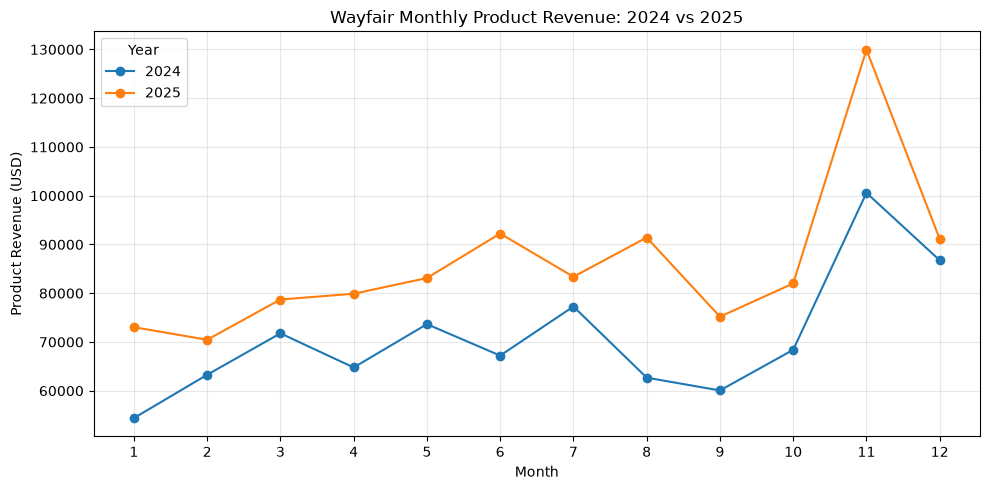

In [54]:

monthly_chart = monthly_revenue.pivot(
    index="month",
    columns="year",
    values="line_revenue"
)

monthly_chart.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Wayfair Monthly Product Revenue: 2024 vs 2025")
plt.xlabel("Month")
plt.ylabel("Product Revenue (USD)")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.legend(title="Year")
plt.tight_layout()

plt.savefig(
    "charts/monthly_revenue_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [55]:
# Calculate revenue by product category


# Add product details to each sales line
sales_with_products = completed_sales.merge(
    products_clean[["product_id", "product_name", "category"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Revenue by category
category_revenue = (
    sales_with_products
    .groupby("category")["line_revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

category_revenue["revenue_share_pct"] = (
    category_revenue["line_revenue"]
    / category_revenue["line_revenue"].sum()
    * 100
)

print(category_revenue.round(2))


    category  line_revenue  revenue_share_pct
0  Furniture     322774.21              17.16
1    Kitchen     279719.21              14.87
2      Decor     277848.70              14.77
3    Bedding     266931.61              14.19
4    Outdoor     247612.23              13.16
5   Lighting     237737.13              12.64
6    Storage     139648.40               7.42
7       Bath     109003.59               5.79


In [56]:
# Find the top 10 products


top_products = (
    sales_with_products
    .groupby("product_name")
    .agg(
        revenue=("line_revenue", "sum"),
        units_sold=("quantity", "sum")
    )
    .sort_values("revenue", ascending=False)
    .head(10)
    .reset_index()
)

print(top_products.round(2))


                product_name   revenue  units_sold
0         Cotton Patio Chair  67034.90         142
1  Classic Dining Chair Pair  52017.94          67
2  Coastal Picture Frame Set  44213.96         310
3              Ceramic Quilt  41379.17         194
4          Bamboo Nightstand  41339.23          77
5              Modern Wreath  40995.15         296
6          Nordic Side Table  40366.49          73
7       Velvet String Lights  38803.92         168
8            Classic Garland  38667.93         288
9           Marble Bookshelf  38595.66          80


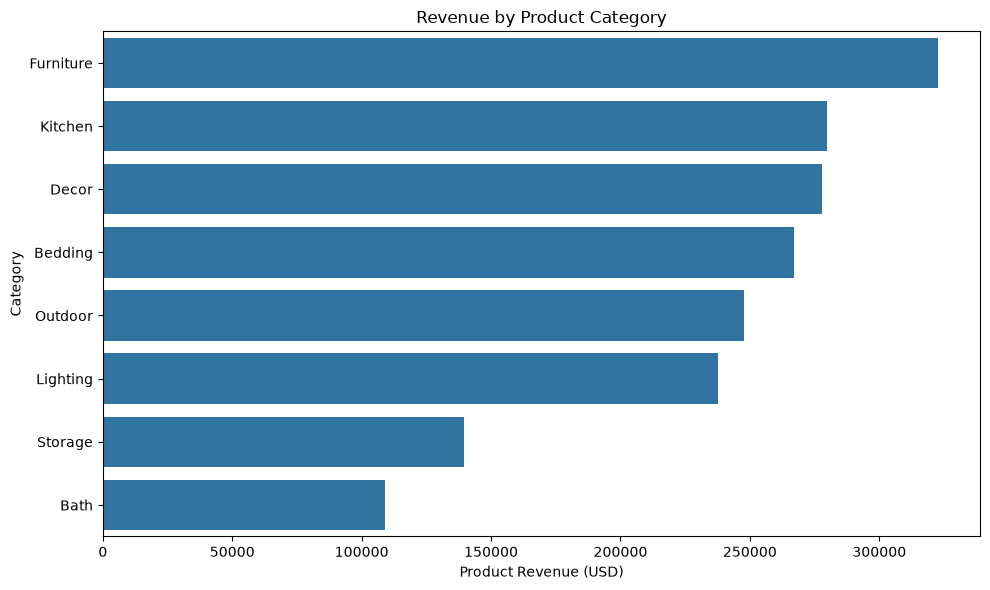

<Figure size 640x480 with 0 Axes>

In [57]:
# Visualize category revenue


plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_revenue,
    x="line_revenue",
    y="category"
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Revenue (USD)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

plt.tight_layout()
plt.savefig("charts/revenue_by_category.png",
            dpi=300, bbox_inches="tight")
plt.show()


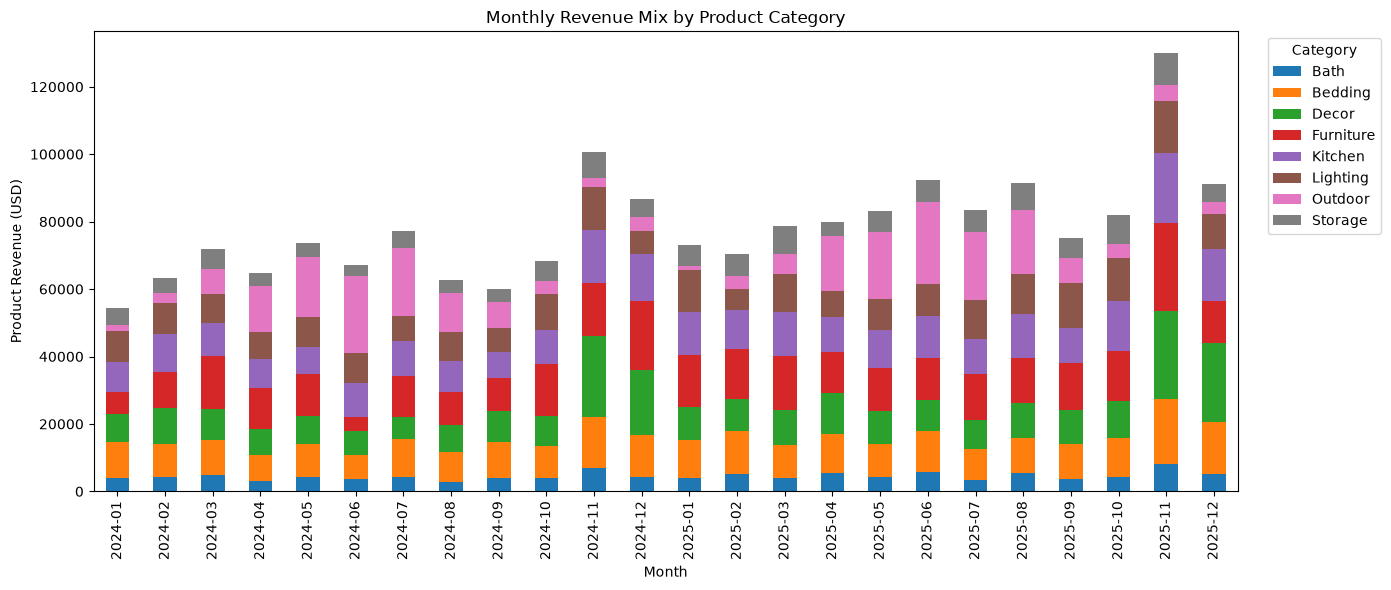

In [58]:

# Analyze category mix by month
sales_with_products["year_month"] = (
    sales_with_products["order_date"].dt.to_period("M")
)

monthly_category = (
    sales_with_products
    .groupby(["year_month", "category"])["line_revenue"]
    .sum()
    .reset_index()
)

category_mix = monthly_category.pivot(
    index="year_month",
    columns="category",
    values="line_revenue"
).fillna(0)

# Create stacked bar chart
category_mix.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 6)
)

plt.title("Monthly Revenue Mix by Product Category")
plt.xlabel("Month")
plt.ylabel("Product Revenue (USD)")
plt.legend(title="Category", bbox_to_anchor=(1.02, 1))
plt.tight_layout()

# Save the chart
plt.savefig(
    "charts/monthly_category_mix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [59]:
# Prepare all order items with their status and category


# Attach order status to every order-item row
all_sales = order_items_clean.merge(
    orders_clean[["order_id", "status"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Attach category information
all_sales = all_sales.merge(
    products_clean[["product_id", "category"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

print("Rows:", len(all_sales))
print("\nStatuses:")
print(all_sales["status"].value_counts())


Rows: 15608

Statuses:
status
completed    14283
returned       766
canceled       559
Name: count, dtype: int64


In [60]:
# Calculate category-level performance


# One record per order and category for status counts
order_category = (
    all_sales[["order_id", "category", "status"]]
    .drop_duplicates()
)

category_status = (
    order_category
    .groupby("category")
    .agg(
        total_orders=("order_id", "nunique"),
        completed_orders=(
            "status", lambda s: (s == "completed").sum()
        ),
        returned_orders=(
            "status", lambda s: (s == "returned").sum()
        ),
        canceled_orders=(
            "status", lambda s: (s == "canceled").sum()
        )
    )
    .reset_index()
)

category_status["return_rate_pct"] = (
    category_status["returned_orders"]
    / category_status["total_orders"] * 100
)

category_status["cancellation_rate_pct"] = (
    category_status["canceled_orders"]
    / category_status["total_orders"] * 100
)

# Completed revenue for each category
category_aov = (
    sales_with_products
    .groupby("category")
    .agg(
        category_revenue=("line_revenue", "sum"),
        completed_orders=("order_id", "nunique")
    )
    .reset_index()
)

category_aov["average_order_value"] = (
    category_aov["category_revenue"]
    / category_aov["completed_orders"]
)

# Combine the metrics
category_performance = category_status.merge(
    category_aov[
        ["category", "category_revenue", "average_order_value"]
    ],
    on="category",
    how="left"
)

print(
    category_performance.sort_values(
        "category_revenue", ascending=False
    ).round(2).to_string(index=False)
)


 category  total_orders  completed_orders  returned_orders  canceled_orders  return_rate_pct  cancellation_rate_pct  category_revenue  average_order_value
Furniture          1007               858              118               31            11.72                   3.08         322774.21               376.19
  Kitchen          2844              2618              118              108             4.15                   3.80         279719.21               106.84
    Decor          2729              2520              114               95             4.18                   3.48         277848.70               110.26
  Bedding          1800              1650               91               59             5.06                   3.28         266931.61               161.78
  Outdoor          1353              1243               60               50             4.43                   3.70         247612.23               199.21
 Lighting          1227              1142               49            

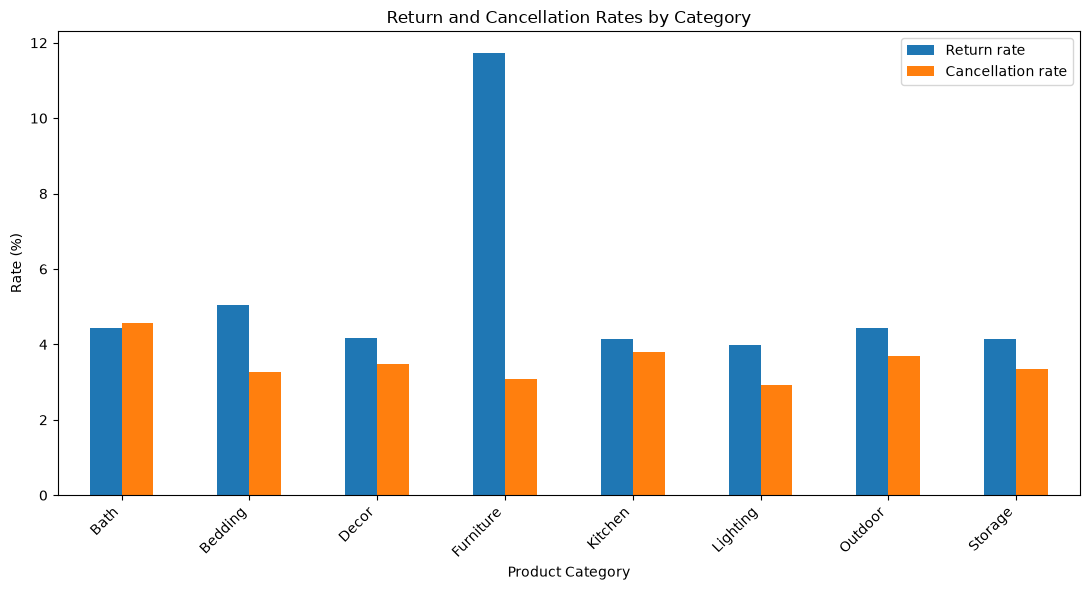

<Figure size 640x480 with 0 Axes>

In [61]:
# Create a chart comparing return and cancellation rates


rates = category_performance.set_index("category")[
    ["return_rate_pct", "cancellation_rate_pct"]
]

rates.plot(kind="bar", figsize=(11, 6))

plt.title("Return and Cancellation Rates by Category")
plt.xlabel("Product Category")
plt.ylabel("Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(["Return rate", "Cancellation rate"])
plt.tight_layout()
plt.show()

plt.tight_layout()
plt.savefig("charts/return_cancellation_rates.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [62]:
# Calculate overall year-over-year growth


# Total product revenue by year
yearly_revenue = (
    completed_sales
    .groupby("year")["line_revenue"]
    .sum()
)

print("Revenue by year:")
print(yearly_revenue.round(2))

# Calculate year-over-year growth
revenue_2024 = yearly_revenue.loc[2024]
revenue_2025 = yearly_revenue.loc[2025]

growth_usd = revenue_2025 - revenue_2024
growth_pct = (growth_usd / revenue_2024) * 100

print(f"\n2024 revenue: ${revenue_2024:,.2f}")
print(f"2025 revenue: ${revenue_2025:,.2f}")
print(f"Revenue change: ${growth_usd:,.2f}")
print(f"Year-over-year growth: {growth_pct:.2f}%")


Revenue by year:
year
2024     850786.45
2025    1030488.63
Name: line_revenue, dtype: float64

2024 revenue: $850,786.45
2025 revenue: $1,030,488.63
Revenue change: $179,702.18
Year-over-year growth: 21.12%
